# DSCI 552 - Homework 6

**Name:** Yiming Xiong  
**USC ID:** 1057091668

## Import Section

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from xgboost import XGBClassifier

## 1(a) Load data

In [2]:
TRAIN_PATH = Path("../data/aps_failure_training_set.csv")
TEST_PATH = Path("../data/aps_failure_test_set.csv")

train_df = pd.read_csv(
    TRAIN_PATH,
    skiprows=20,
    na_values="na",
)

test_df = pd.read_csv(
    TEST_PATH,
    skiprows=20,
    na_values="na",
)

print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")
display(train_df.head())

Training set shape: (60000, 171)
Test set shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## 1(b)

### (i) Median Imputation for Missing Data

Common methods for handling missing values include removing incomplete rows, filling missing values with the mean or median, and using model-based imputation. Here, I use median imputation. The median is less affected by extreme values than the mean.

In [3]:
X_train = train_df.drop(columns="class").copy()
y_train = train_df["class"].copy()

X_test = test_df.drop(columns="class").copy()
y_test = test_df["class"].copy()

missing_train_before = X_train.isna().sum().sum()
missing_test_before = X_test.isna().sum().sum()

train_imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(
    train_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

test_imputer = SimpleImputer(strategy="median")
X_test = pd.DataFrame(
    test_imputer.fit_transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

print(f"Missing values before imputation: train={missing_train_before}, test={missing_test_before}")
print(f"Missing values after imputation: train={X_train.isna().sum().sum()}, test={X_test.isna().sum().sum()}")

Missing values before imputation: train=850015, test=228680
Missing values after imputation: train=0, test=0


### (ii) Coefficient of Variation

In [4]:
feature_mean = X_train.mean()
feature_std = X_train.std(ddof=1)

cv_values = (feature_std / feature_mean).replace([np.inf, -np.inf], np.nan)
cv_table = pd.DataFrame({ "mean": feature_mean, "sample_std": feature_std, "CV": cv_values,}).sort_values("CV", ascending=False)

display(cv_table)

,mean,sample_std,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


### (iii) Feature Correlation Matrix

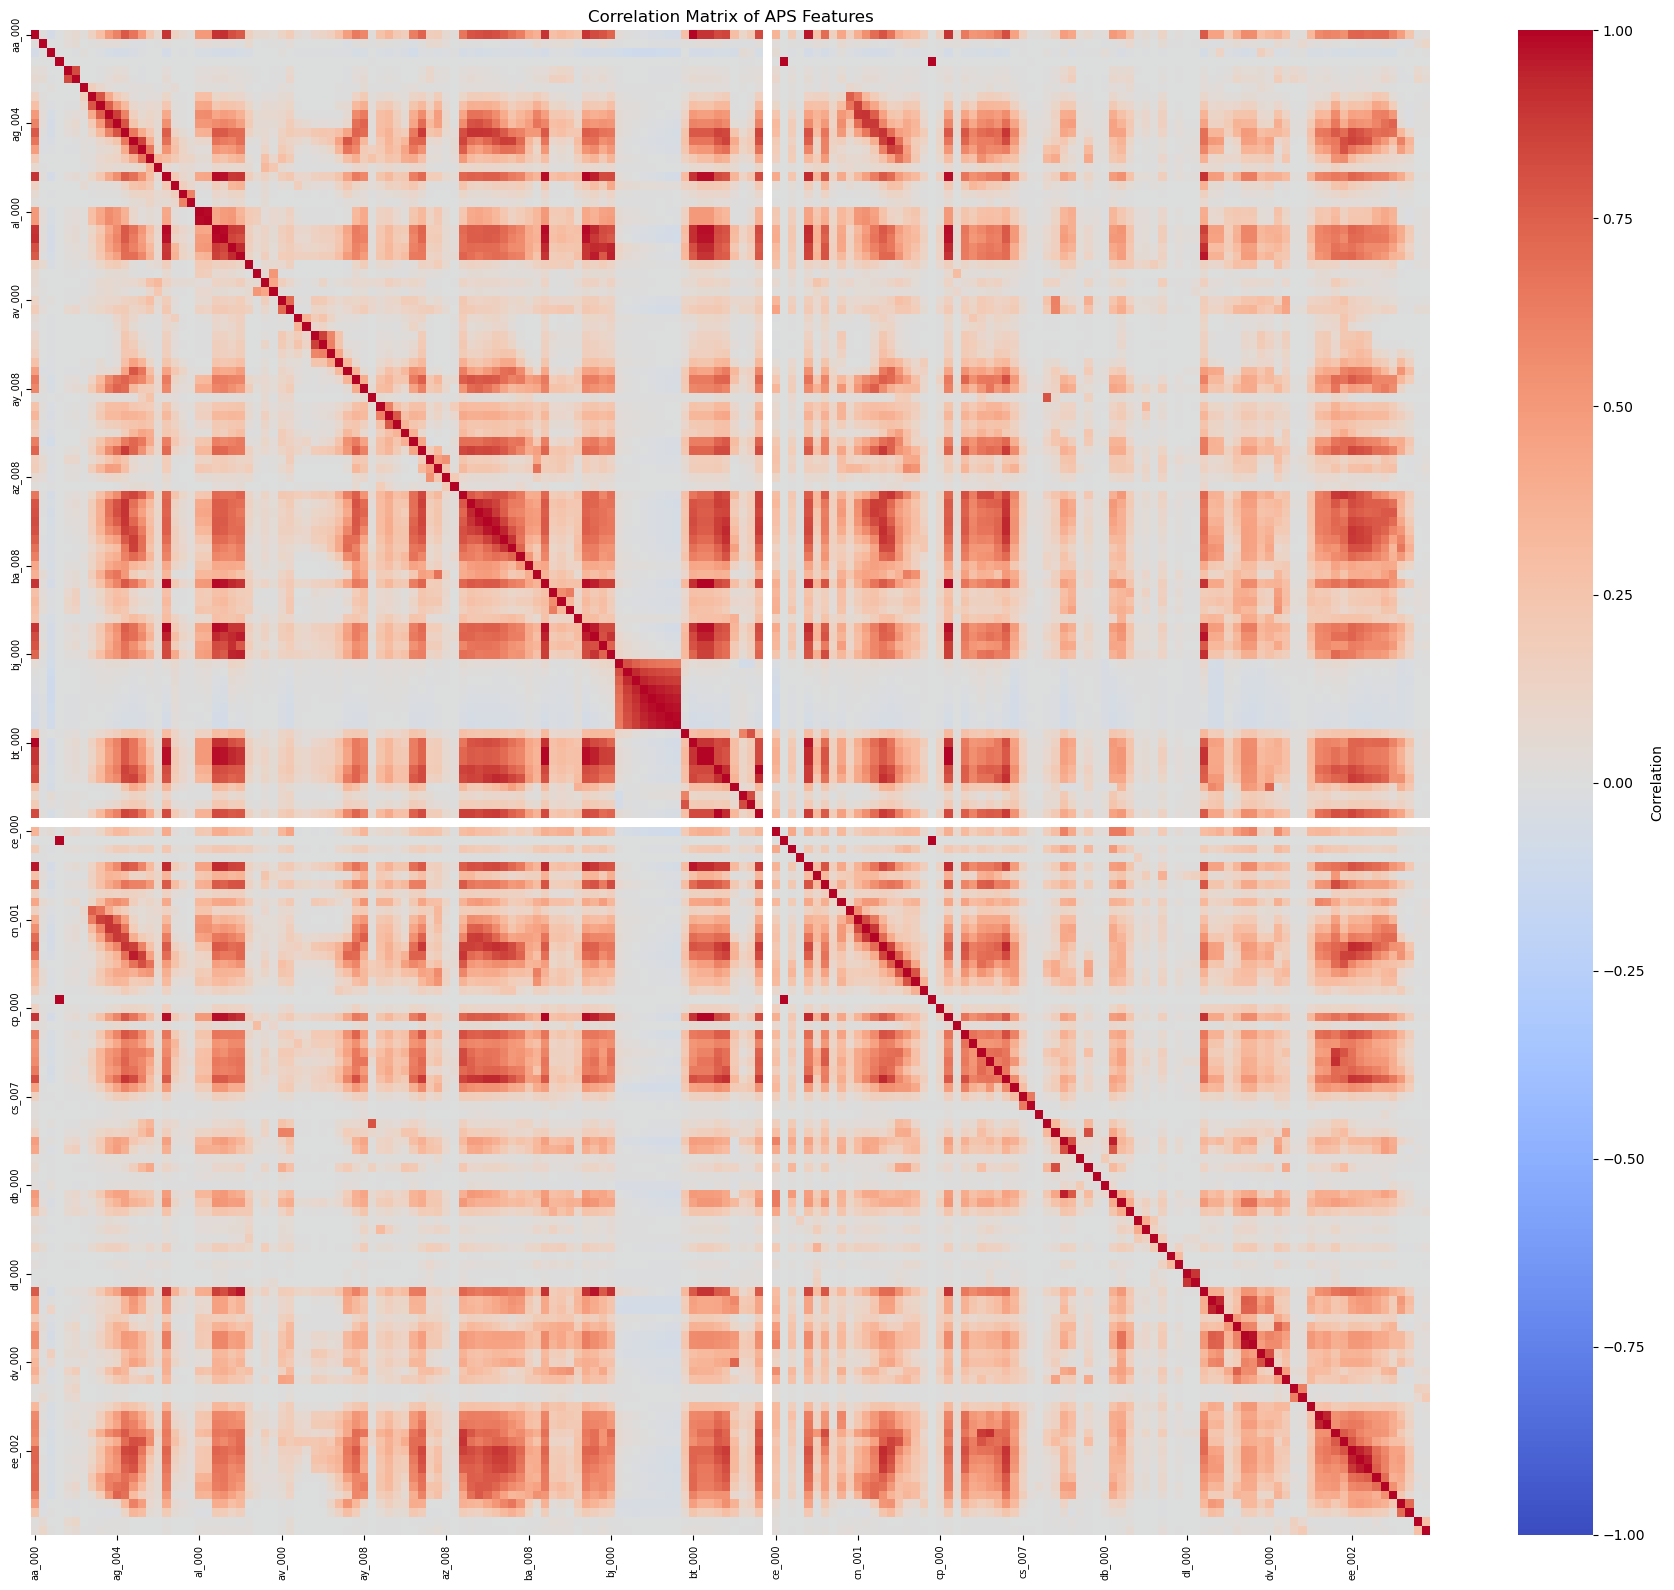

In [5]:
correlation_matrix = X_train.corr()

fig, ax = plt.subplots(figsize=(18, 16))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10,
    cbar_kws={"label": "Correlation"},
    ax=ax,
)

ax.set_title("Correlation Matrix of APS Features")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### (iv) Visualization of the Features with the Highest CV

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


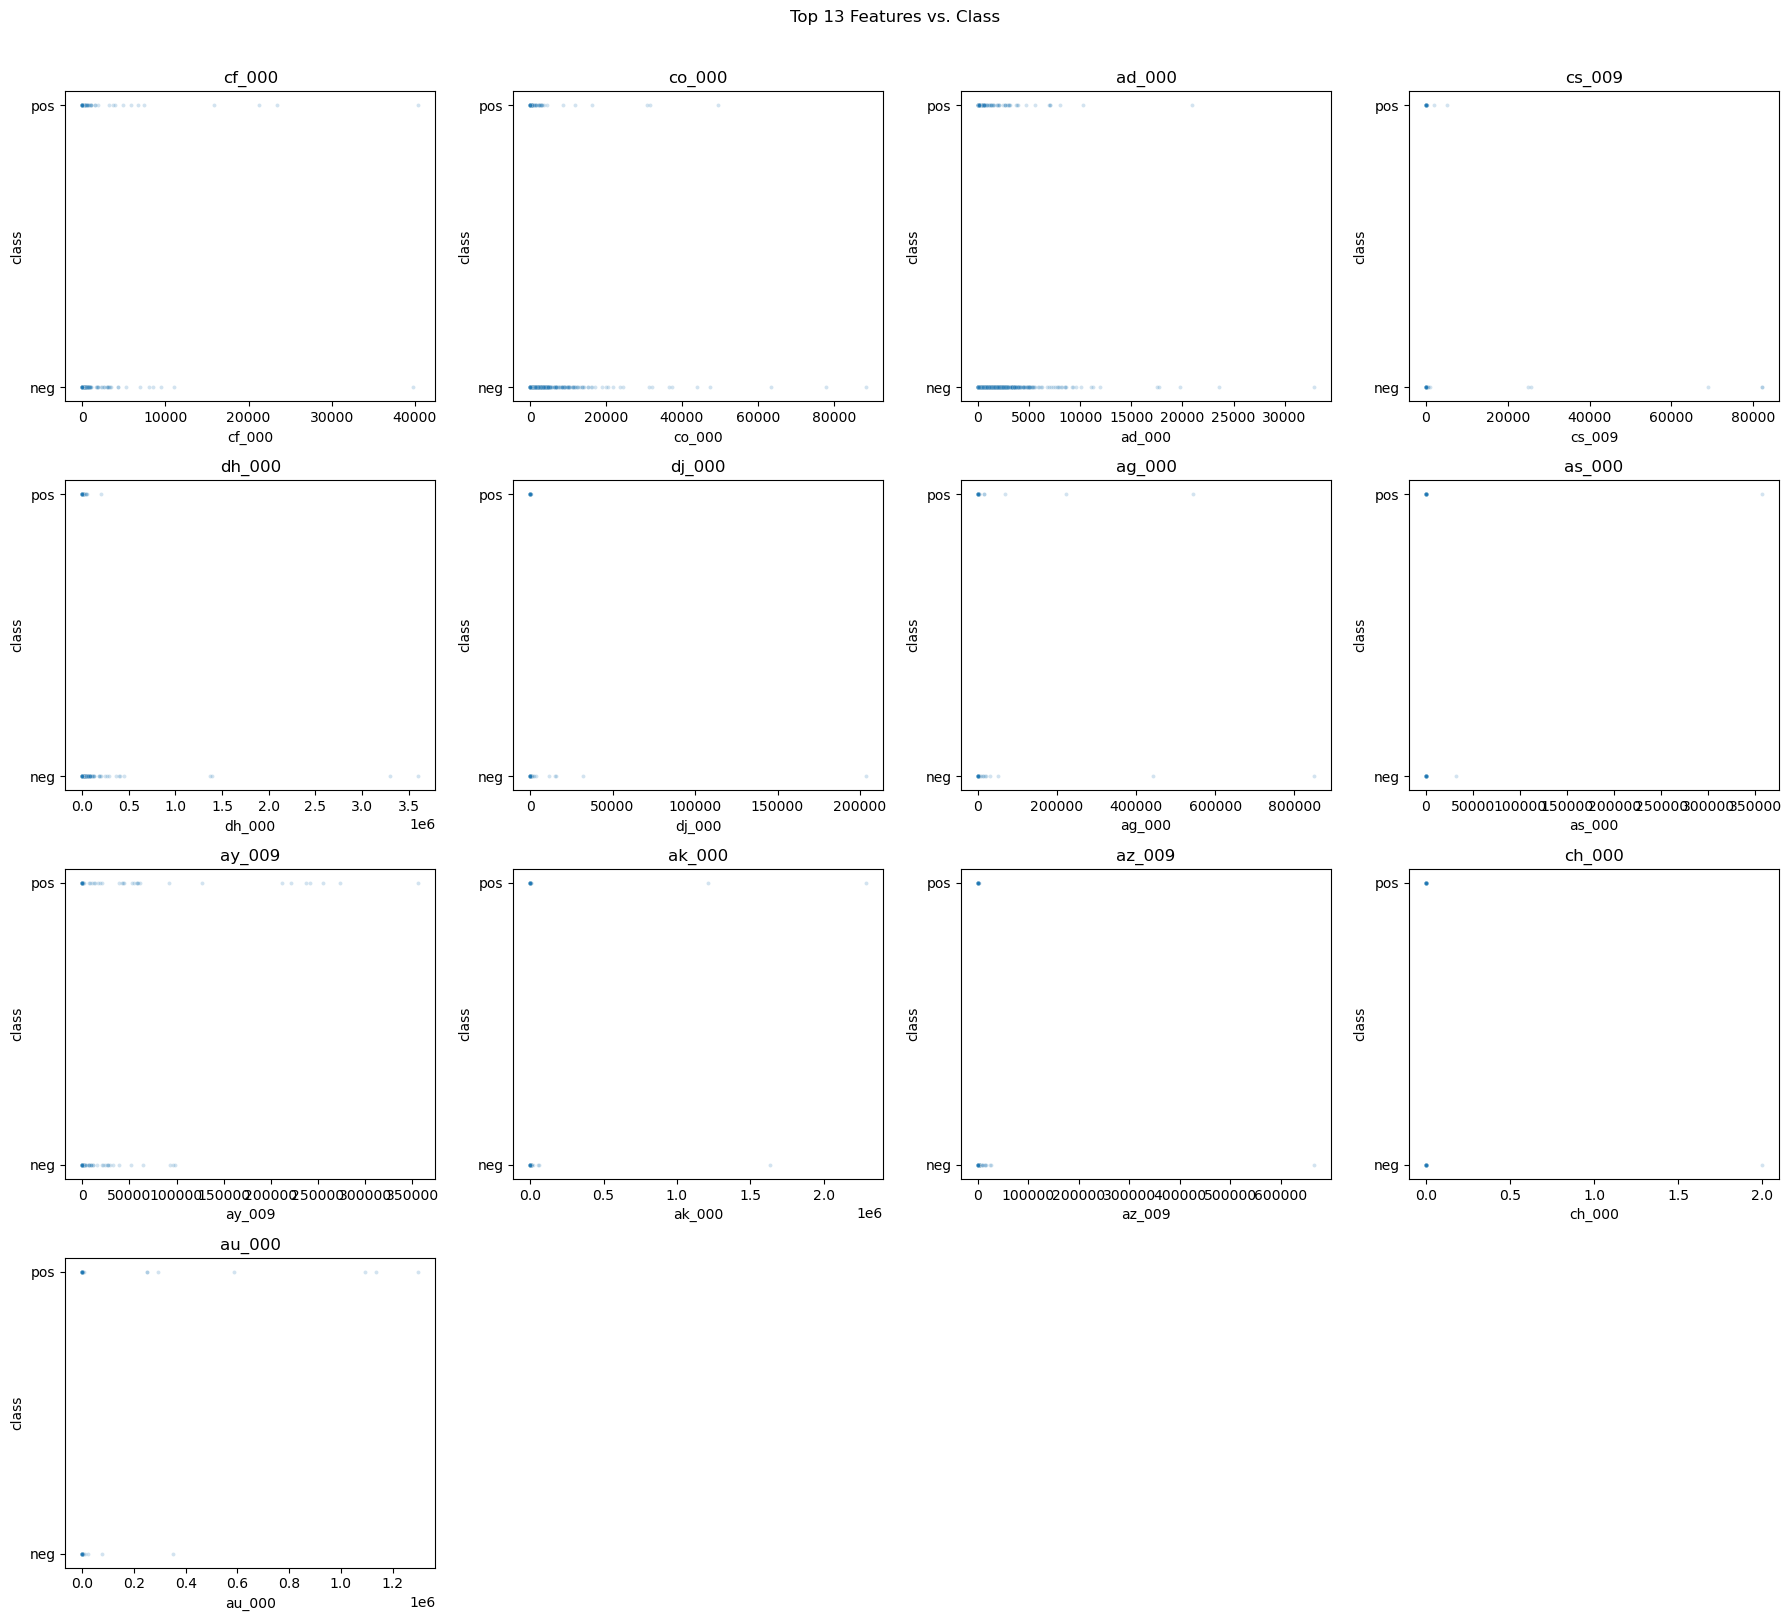

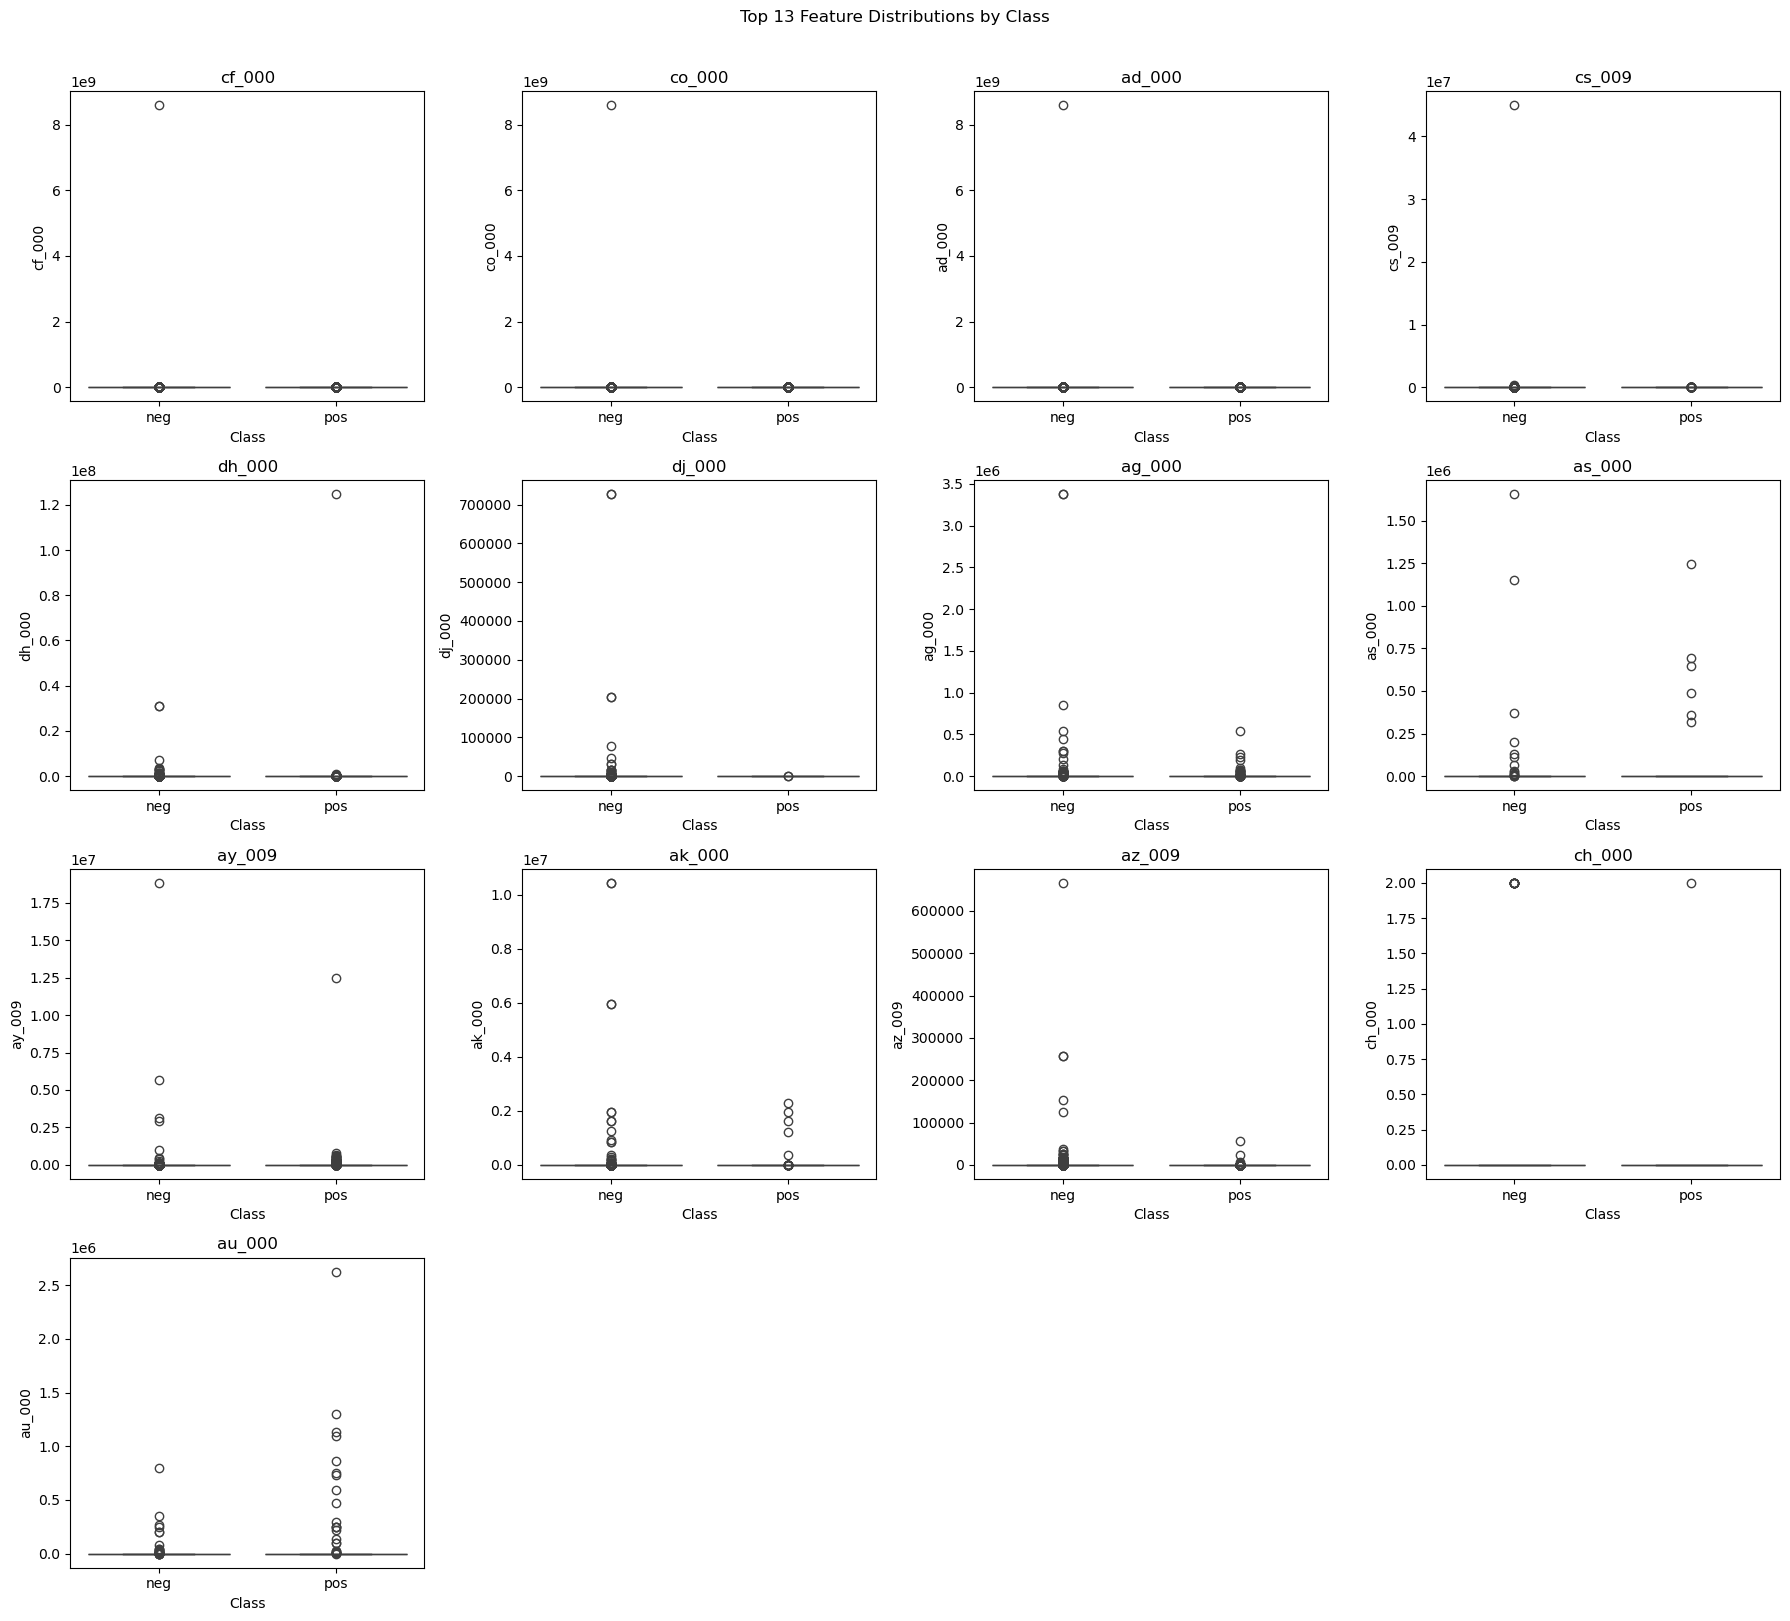

In [6]:
n_top_features = int(np.sqrt(X_train.shape[1]))
top_features = cv_table.head(n_top_features).index.tolist()

display(cv_table.loc[top_features, ["CV"]])

# Sample rows for clearer scatter plots
plot_index = X_train.sample(
    n=min(10000, len(X_train)),
    random_state=552,
).index
y_train_binary = y_train.map({"neg": 0, "pos": 1})

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, feature in zip(axes.flat, top_features):
    sns.scatterplot(
        x=X_train.loc[plot_index, feature],
        y=y_train_binary.loc[plot_index],
        ax=ax,
        s=8,
        alpha=0.2,
    )
    ax.set_title(feature)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["neg", "pos"])

for ax in axes.flat[n_top_features:]:
    ax.remove()

fig.suptitle("Top 13 Features vs. Class", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(x=y_train, y=X_train[feature], ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Class")

for ax in axes.flat[n_top_features:]:
    ax.remove()

fig.suptitle("Top 13 Feature Distributions by Class", y=1.01)
plt.tight_layout()
plt.show()

The boxplots compare the distributions of the 13 features with the highest coefficients of variation (CV) between the negative and positive classes. Many features have extreme outliers, which stretch the y-axis and make the boxes appear compressed near zero, making them difficult to compare; these plots alone cannot determine whether the features are significant.

### (v) Pos and Neg Class Imbalance

In [7]:
class_counts = y_train.value_counts()
class_percentages = y_train.value_counts(normalize=True) * 100

display(pd.DataFrame({"count": class_counts, "percentage": class_percentages}))

print(f"Negative-to-positive ratio: {class_counts['neg'] / class_counts['pos']:.0f}:1")

,count,percentage
class,,
neg,59000,98.333333
pos,1000,1.666667


Negative-to-positive ratio: 59:1


## 1(c) Unbalanced Random Forest

In [8]:
unbalanced_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=552,
    oob_score=True,
    n_jobs=-1,
)

unbalanced_rf.fit(X_train, y_train)

y_train_pred = unbalanced_rf.predict(X_train)
y_test_pred = unbalanced_rf.predict(X_test)

pos_index = list(unbalanced_rf.classes_).index("pos")
y_train_prob = unbalanced_rf.predict_proba(X_train)[:, pos_index]
y_test_prob = unbalanced_rf.predict_proba(X_test)[:, pos_index]

train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
oob_error = 1 - unbalanced_rf.oob_score_

train_auc = roc_auc_score(y_train.eq("pos"), y_train_prob)
test_auc = roc_auc_score(y_test.eq("pos"), y_test_prob)

In [9]:
print(f"Training misclassification error: {train_error:.4f}")
print(f"Test misclassification error: {test_error:.4f}")
print(f"OOB error: {oob_error:.4f}")
print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC: {test_auc:.4f}")

Training misclassification error: 0.0000
Test misclassification error: 0.0079
OOB error: 0.0061
Training AUC: 1.0000
Test AUC: 0.9930


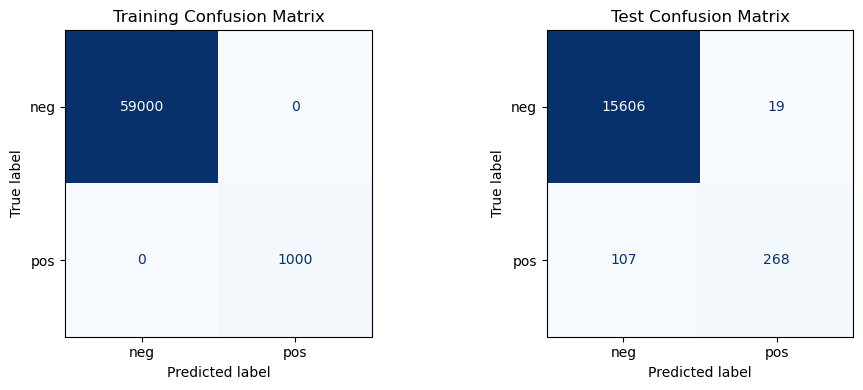

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    labels=["neg", "pos"],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=["neg", "pos"],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

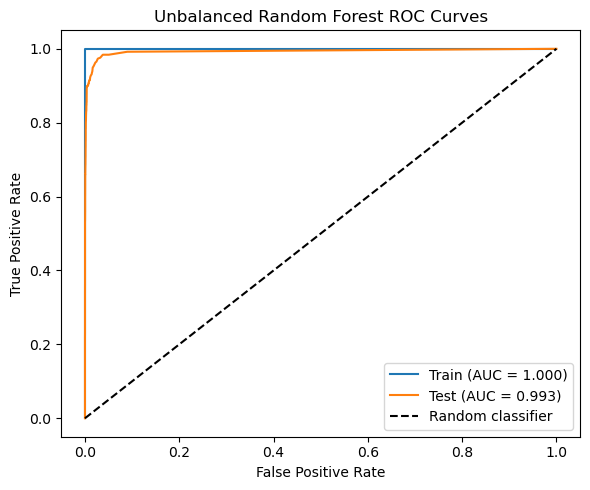

In [11]:
y_train_binary = y_train.eq("pos").astype(int)
y_test_binary = y_test.eq("pos").astype(int)

train_fpr, train_tpr, _ = roc_curve(y_train_binary, y_train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_binary, y_test_prob)

plt.figure(figsize=(6, 5))
plt.plot(train_fpr, train_tpr, label=f"Train (AUC = {train_auc:.3f})")
plt.plot(test_fpr, test_tpr, label=f"Test (AUC = {test_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Unbalanced Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The Random Forest achieved a test misclassification error of 0.0079 and a test AUC of 0.993. The OOB error was 0.0061, which is close to the test error. However, the test confusion matrix shows that 107 of the 375 positive cases were classified as negative, giving a positive-class recall of about 71.5%. Although the test error was low, the model missed 107 positive examples.

## 1(d) Random Forest with Class Weighting

I use class_weight= `balanced_subsample`. It assigns class weights based on the class frequencies in each bootstrap sample, giving more weight to the minority class. The test results show that this setting did not improve recall in this run.

In [12]:
balanced_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=552,
    oob_score=True,
    n_jobs=-1,
)

balanced_rf.fit(X_train, y_train)

y_train_pred_balanced = balanced_rf.predict(X_train)
y_test_pred_balanced = balanced_rf.predict(X_test)

pos_index = list(balanced_rf.classes_).index("pos")
y_train_prob_balanced = balanced_rf.predict_proba(X_train)[:, pos_index]
y_test_prob_balanced = balanced_rf.predict_proba(X_test)[:, pos_index]

train_error_balanced = 1 - accuracy_score(y_train, y_train_pred_balanced)
test_error_balanced = 1 - accuracy_score(y_test, y_test_pred_balanced)
oob_error_balanced = 1 - balanced_rf.oob_score_

train_auc_balanced = roc_auc_score(y_train.eq("pos"), y_train_prob_balanced)
test_auc_balanced = roc_auc_score(y_test.eq("pos"), y_test_prob_balanced)

In [13]:
print(f"Training misclassification error: {train_error_balanced:.4f}")
print(f"Test misclassification error: {test_error_balanced:.4f}")
print(f"OOB error: {oob_error_balanced:.4f}")
print(f"Training AUC: {train_auc_balanced:.4f}")
print(f"Test AUC: {test_auc_balanced:.4f}")

Training misclassification error: 0.0000
Test misclassification error: 0.0112
OOB error: 0.0079
Training AUC: 1.0000
Test AUC: 0.9903


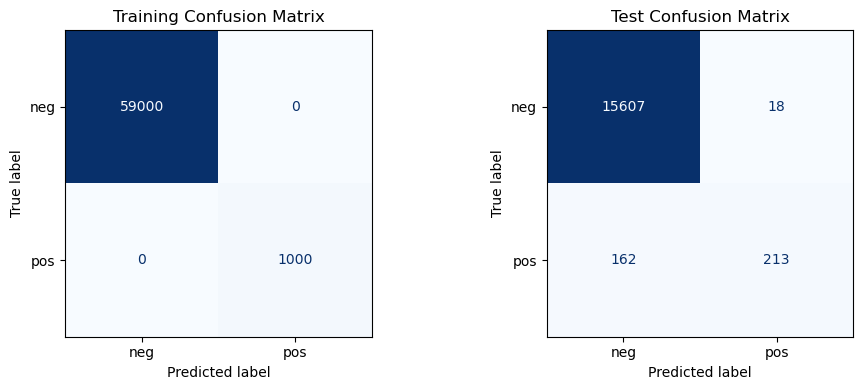

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred_balanced,
    labels=["neg", "pos"],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_balanced,
    labels=["neg", "pos"],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

train_fpr_balanced, train_tpr_balanced, _ = roc_curve(
    y_train.eq("pos"), y_train_prob_balanced
)
test_fpr_balanced, test_tpr_balanced, _ = roc_curve(
    y_test.eq("pos"), y_test_prob_balanced
)


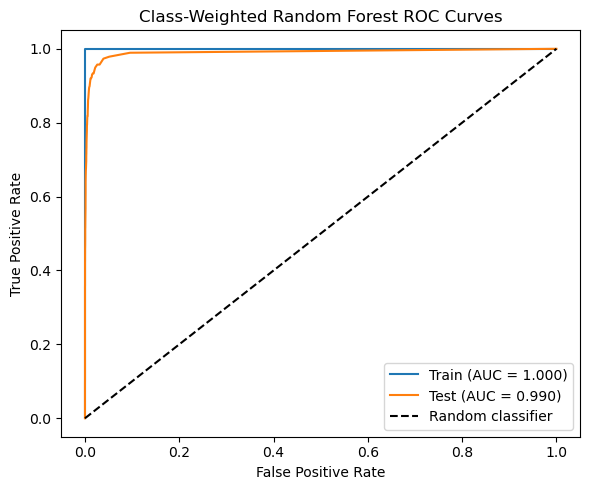

In [15]:
plt.figure(figsize=(6, 5))
plt.plot(
    train_fpr_balanced,
    train_tpr_balanced,
    label=f"Train (AUC = {train_auc_balanced:.3f})",
)
plt.plot(
    test_fpr_balanced,
    test_tpr_balanced,
    label=f"Test (AUC = {test_auc_balanced:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Class-Weighted Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The class-weighted Random Forest had a test misclassification error of 0.0112 and a test AUC of 0.9903, compared with 0.0079 and 0.9930 for the unweighted Random Forest. Its positive-class recall also decreased from 71.5% to 56.8%. Thus, class weighting did not improve the test-set results in this run.

## 1(e) XGBoost with L1 Regularization

In [16]:
y_train_binary = y_train.map({"neg": 0, "pos": 1})
y_test_binary = y_test.map({"neg": 0, "pos": 1})

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=552,
    n_jobs=-1,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=552,
)

xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
)

xgb_search.fit(X_train, y_train_binary)
best_xgb = xgb_search.best_estimator_

cv_results = pd.DataFrame({
    "reg_alpha": [
        params["reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "mean_cv_accuracy": xgb_search.cv_results_["mean_test_score"],
})
cv_results["mean_cv_error"] = 1 - cv_results["mean_cv_accuracy"]
display(cv_results.sort_values("mean_cv_accuracy", ascending=False))

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,reg_alpha,mean_cv_accuracy,mean_cv_error
1,0.01,0.993000,0.007000
2,0.10,0.992967,0.007033
3,1.00,0.992967,0.007033
0,0.00,0.992917,0.007083
4,10.00,0.992200,0.007800


In [17]:
y_train_pred_xgb = best_xgb.predict(X_train)
y_test_pred_xgb = best_xgb.predict(X_test)

y_train_prob_xgb = best_xgb.predict_proba(X_train)[:, 1]
y_test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

train_error_xgb = 1 - accuracy_score(y_train_binary, y_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test_binary, y_test_pred_xgb)
train_auc_xgb = roc_auc_score(y_train_binary, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_binary, y_test_prob_xgb)

In [18]:
print(f"Selected reg_alpha: {xgb_search.best_params_['reg_alpha']}")
print(f"Mean 5-fold CV error: {1 - xgb_search.best_score_:.4f}")
print(f"Training misclassification error: {train_error_xgb:.4f}")
print(f"Test misclassification error: {test_error_xgb:.4f}")
print(f"Training AUC: {train_auc_xgb:.4f}")
print(f"Test AUC: {test_auc_xgb:.4f}")

Selected reg_alpha: 0.01
Mean 5-fold CV error: 0.0070
Training misclassification error: 0.0047
Test misclassification error: 0.0084
Training AUC: 0.9953
Test AUC: 0.9961


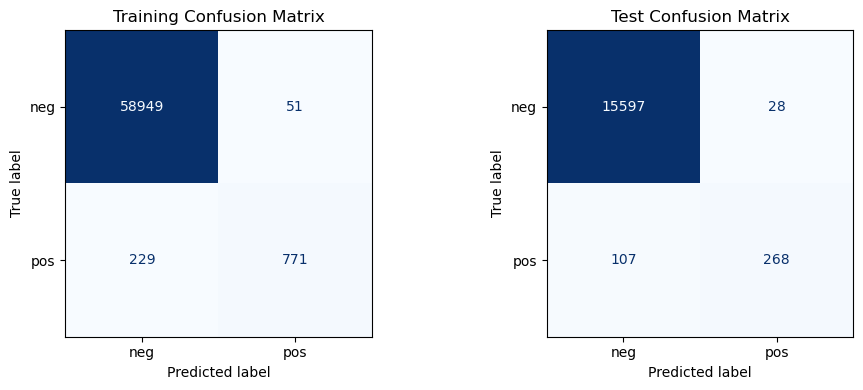

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train_binary,
    y_train_pred_xgb,
    labels=[0, 1],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_test_pred_xgb,
    labels=[0, 1],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

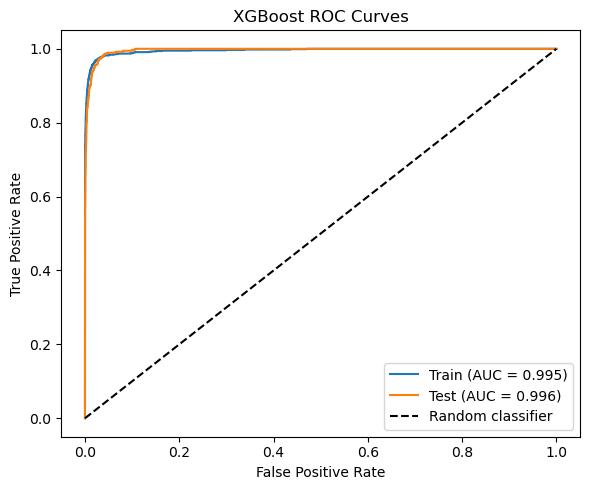

In [20]:
train_fpr_xgb, train_tpr_xgb, _ = roc_curve(
    y_train_binary, y_train_prob_xgb
)
test_fpr_xgb, test_tpr_xgb, _ = roc_curve(
    y_test_binary, y_test_prob_xgb
)

plt.figure(figsize=(6, 5))
plt.plot(
    train_fpr_xgb,
    train_tpr_xgb,
    label=f"Train (AUC = {train_auc_xgb:.3f})",
)
plt.plot(
    test_fpr_xgb,
    test_tpr_xgb,
    label=f"Test (AUC = {test_auc_xgb:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The selected L1 regularization parameter was `reg_alpha = 0.01`, which gave the highest mean 5-fold cross-validation accuracy. The cross-validation error was 0.0070, and the test error was 0.0084. The test AUC was 0.9961.

## 1(f) XGBoost with SMOTE

In [22]:
smote_xgb_pipeline = ImbPipeline(steps=[
    ("smote", SMOTE(random_state=552)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=552,
        n_jobs=-1,
    )),
])

smote_xgb_search = GridSearchCV(
    estimator=smote_xgb_pipeline,
    param_grid={"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
)

smote_xgb_search.fit(X_train, y_train_binary)
best_smote_xgb = smote_xgb_search.best_estimator_

smote_cv_results = pd.DataFrame({
    "reg_alpha": [
        params["xgb__reg_alpha"]
        for params in smote_xgb_search.cv_results_["params"]
    ],
    "mean_cv_accuracy": smote_xgb_search.cv_results_["mean_test_score"],
})
smote_cv_results["mean_cv_error"] = 1 - smote_cv_results["mean_cv_accuracy"]

display(smote_cv_results.sort_values("mean_cv_accuracy", ascending=False))

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,reg_alpha,mean_cv_accuracy,mean_cv_error
2,0.10,0.979800,0.020200
0,0.00,0.979733,0.020267
1,0.01,0.979583,0.020417
3,1.00,0.979567,0.020433
4,10.00,0.979050,0.020950


In [23]:
y_train_pred_smote = best_smote_xgb.predict(X_train)
y_test_pred_smote = best_smote_xgb.predict(X_test)

y_train_prob_smote = best_smote_xgb.predict_proba(X_train)[:, 1]
y_test_prob_smote = best_smote_xgb.predict_proba(X_test)[:, 1]

train_error_smote = 1 - accuracy_score(y_train_binary, y_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_binary, y_test_pred_smote)
train_auc_smote = roc_auc_score(y_train_binary, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_binary, y_test_prob_smote)

In [24]:
print(f"Selected reg_alpha: {smote_xgb_search.best_params_['xgb__reg_alpha']}")
print(f"Mean 5-fold CV error: {1 - smote_xgb_search.best_score_:.4f}")
print(f"Training misclassification error: {train_error_smote:.4f}")
print(f"Test misclassification error: {test_error_smote:.4f}")
print(f"Training AUC: {train_auc_smote:.4f}")
print(f"Test AUC: {test_auc_smote:.4f}")

Selected reg_alpha: 0.1
Mean 5-fold CV error: 0.0202
Training misclassification error: 0.0198
Test misclassification error: 0.0207
Training AUC: 0.9937
Test AUC: 0.9941


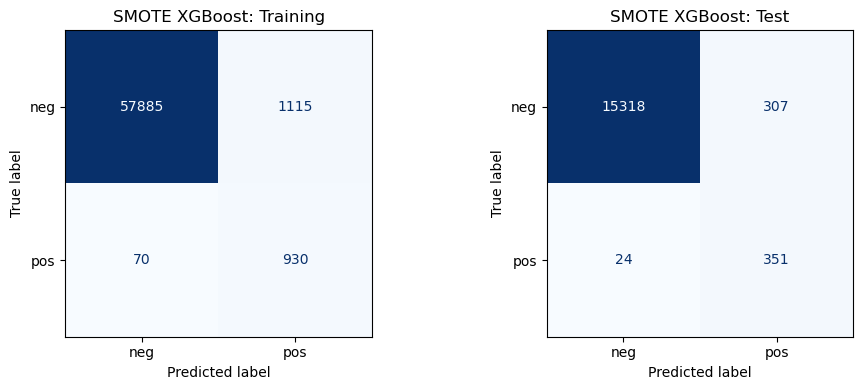

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train_binary,
    y_train_pred_smote,
    labels=[0, 1],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("SMOTE XGBoost: Training")

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_test_pred_smote,
    labels=[0, 1],
    display_labels=["neg", "pos"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("SMOTE XGBoost: Test")

plt.tight_layout()
plt.show()

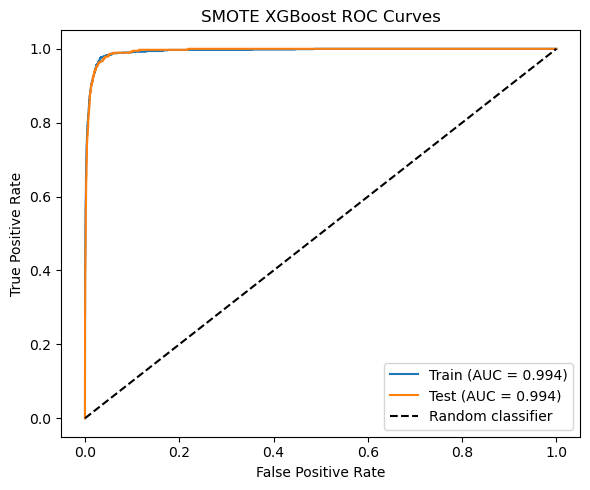

In [26]:
train_fpr_smote, train_tpr_smote, _ = roc_curve(
    y_train_binary, y_train_prob_smote
)
test_fpr_smote, test_tpr_smote, _ = roc_curve(
    y_test_binary, y_test_prob_smote
)

plt.figure(figsize=(6, 5))
plt.plot(
    train_fpr_smote,
    train_tpr_smote,
    label=f"Train (AUC = {train_auc_smote:.3f})",
)
plt.plot(
    test_fpr_smote,
    test_tpr_smote,
    label=f"Test (AUC = {test_auc_smote:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE XGBoost ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
smote_comparison = pd.DataFrame({
    "model": ["XGBoost without SMOTE", "XGBoost with SMOTE"],
    "selected_reg_alpha": [
        xgb_search.best_params_["reg_alpha"],
        smote_xgb_search.best_params_["xgb__reg_alpha"],
    ],
    "mean_5fold_cv_error": [
        1 - xgb_search.best_score_,
        1 - smote_xgb_search.best_score_,
    ],
    "test_error": [
        test_error_xgb,
        test_error_smote,
    ],
    "test_auc": [
        test_auc_xgb,
        test_auc_smote,
    ],
})

display(smote_comparison)

,model,selected_reg_alpha,mean_5fold_cv_error,test_error,test_auc
0,XGBoost without SMOTE,0.01,0.0070,0.008437,0.996065
1,XGBoost with SMOTE,0.10,0.0202,0.020687,0.994059


SMOTE reduced the number of false negatives on the test set from 107 to 24, increasing positive-class recall from 71.5% to 93.6%. However, the number of false positives increased from 28 to 307, so the test error rose from 0.0084 to 0.0207. The test AUC remained high but decreased slightly, from 0.9961 to 0.9941.

## 2. ISLR 6.6.3

| Part | Quantity | Correct choice | Justification |
|---|---|---|---|
| (a) | Training RSS | **iv. Steadily decrease** | Increasing $s$ relaxes the constraint, allowing the model to fit the training data at least as well. |
| (b) | Test RSS | **ii. Decrease initially, then eventually increase in a U shape** | Initially, greater flexibility reduces bias. With too much flexibility, variance and overfitting can increase test RSS. |
| (c) | Variance | **iii. Steadily increase** | A more flexible model is more sensitive to changes in the training data. |
| (d) | Squared bias | **iv. Steadily decrease** | Relaxing the constraint allows the model to better capture the underlying relationship. |
| (e) | Irreducible error | **v. Remain constant** | Irreducible error comes from inherent noise in the data and does not depend on $s$. |

## 3. ISLR, 6.6.5

Let $x_1=x_{11}=x_{12}$ and $x_2=x_{21}=x_{22}$. The problem states that the intercept estimate is zero.

#### (a) Ridge regression optimization problem

The ridge objective in this setting is

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_1-\beta_2x_1)^2
+(y_2-\beta_1x_2-\beta_2x_2)^2
+\lambda(\beta_1^2+\beta_2^2)
\right].
$$

#### (b) The ridge coefficient estimates satisfy $\hat{\beta}_1=\hat{\beta}_2$

Let

$$
A=x_1^2+x_2^2,\qquad B=y_1x_1+y_2x_2.
$$

Ignoring terms that do not depend on the coefficients, the ridge objective can be written as

$$
-2B(\beta_1+\beta_2)
+A(\beta_1+\beta_2)^2
+\lambda(\beta_1^2+\beta_2^2).
$$

The two first-order conditions are

$$
-2B+2A(\beta_1+\beta_2)+2\lambda\beta_1=0
$$

and

$$
-2B+2A(\beta_1+\beta_2)+2\lambda\beta_2=0.
$$

Subtracting the equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Since $\lambda>0$, the ridge estimates must satisfy

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}.
$$

#### (c) Lasso optimization problem

The lasso objective in this setting is

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_1-\beta_2x_1)^2
+(y_2-\beta_1x_2-\beta_2x_2)^2
+\lambda(|\beta_1|+|\beta_2|)
\right].
$$

#### (d) The lasso coefficient estimates are not unique

Let $t=\beta_1+\beta_2$. Since $x_2=-x_1$ and $y_2=-y_1$, the residual sum of squares becomes

$$
(y_1-tx_1)^2+(y_2-tx_2)^2
=2(y_1-tx_1)^2.
$$

For any fixed $t$, the smallest possible value of $|\beta_1|+|\beta_2|$ is $|t|$. This minimum is attained whenever $\beta_1$ and $\beta_2$ have the same sign, or one coefficient is zero. Therefore, multiple coefficient pairs can give the same fitted values and the same lasso penalty.

For example, if the optimal sum $\hat{t}$ is positive, every pair satisfying

$$
\beta_1\geq 0,\qquad
\beta_2\geq 0,\qquad
\beta_1+\beta_2=\hat{t}
$$

gives the same objective value. If $\hat{t}$ is negative, the same is true for pairs with both coefficients nonpositive and with sum $\hat{t}$. Thus, when the optimal sum is nonzero, the lasso coefficient estimates are not unique.

In the constrained form, the lasso minimizes the residual sum of squares subject to $|\beta_1|+|\beta_2|\leq s$. If the constraint is too restrictive to allow the unconstrained optimal sum $y_1/x_1$, the optimal coefficient sum lies at the feasible boundary. If the constraint allows that sum, the fitted values are optimized whenever $\beta_1+\beta_2=y_1/x_1$; multiple coefficient pairs can still produce that same sum.

## 4. ISLR 8.4.5

The ten estimated probabilities that the observation belongs to the Red class are

$$
0.1,\;0.15,\;0.2,\;0.2,\;0.55,\;0.6,\;0.6,\;0.65,\;0.7,\;0.75.
$$

**Majority vote:** Six probabilities are greater than $0.5$, so six trees classify the observation as Red. The remaining four classify it as Green. Therefore, the majority-vote classification is **Red**.

**Average probability:** The mean estimated probability for the Red class is

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45.
$$

Since $0.45<0.5$, the average-probability classification is **Green**.

## 5. ISLR 9.7.3

#### (a) Plot the observations

The red observations are $(3,4)$, $(2,2)$, $(4,4)$, and $(1,4)$. The blue observations are $(2,1)$, $(4,3)$, and $(4,1)$.

#### (b) Find the optimal separating hyperplane

The red support vectors $(2,2)$ and $(4,4)$ lie on the line $X_2=X_1$. The blue support vectors $(2,1)$ and $(4,3)$ lie on the parallel line $X_2=X_1-1$. Therefore, the maximal margin hyperplane lies halfway between them:

$$
X_2=X_1-\frac{1}{2}.
$$

An equivalent equation in the form $\beta_0+\beta_1X_1+\beta_2X_2=0$ is

$$
1-2X_1+2X_2=0.
$$

#### (c) State the classification rule

Classify an observation as Red if

$$
1-2X_1+2X_2>0,
$$

and classify it as Blue otherwise. Thus,

$$
\beta_0=1,\qquad \beta_1=-2,\qquad \beta_2=2.
$$

#### (d) Indicate the margin

The two margin boundaries are

$$
1-2X_1+2X_2=1
\quad\text{and}\quad
1-2X_1+2X_2=-1.
$$

Equivalently, they are $X_2=X_1$ and $X_2=X_1-1$. The distance from the separating hyperplane to either margin is $1/\sqrt{8}$, so the full margin width is $1/\sqrt{2}$.

#### (e) Identify the support vectors

The support vectors are observations 2, 3, 5, and 6. They lie on the two margin boundaries.

#### (f) Explain the effect of moving observation 7

Observation 7 is $(4,1)$. It is not a support vector and lies well outside the margin. A small movement of this observation will not change the maximal margin hyperplane, provided it remains away from the margin.

#### (g) Give a non-optimal separating hyperplane

One non-optimal hyperplane is

$$
X_2=X_1-0.8,
$$

or, equivalently,

$$
4-5X_1+5X_2=0.
$$

It still separates all the red and blue observations, but it is closer to the blue observations than the maximal margin hyperplane is, so it does not maximize the margin.

#### (h) Add an observation so the classes are no longer linearly separable

Add a Blue observation at $(1,3)$. The convex hull of the blue observations then contains the Red observation $(2,2)$. Therefore, no hyperplane can separate all the red observations from all the blue observations.

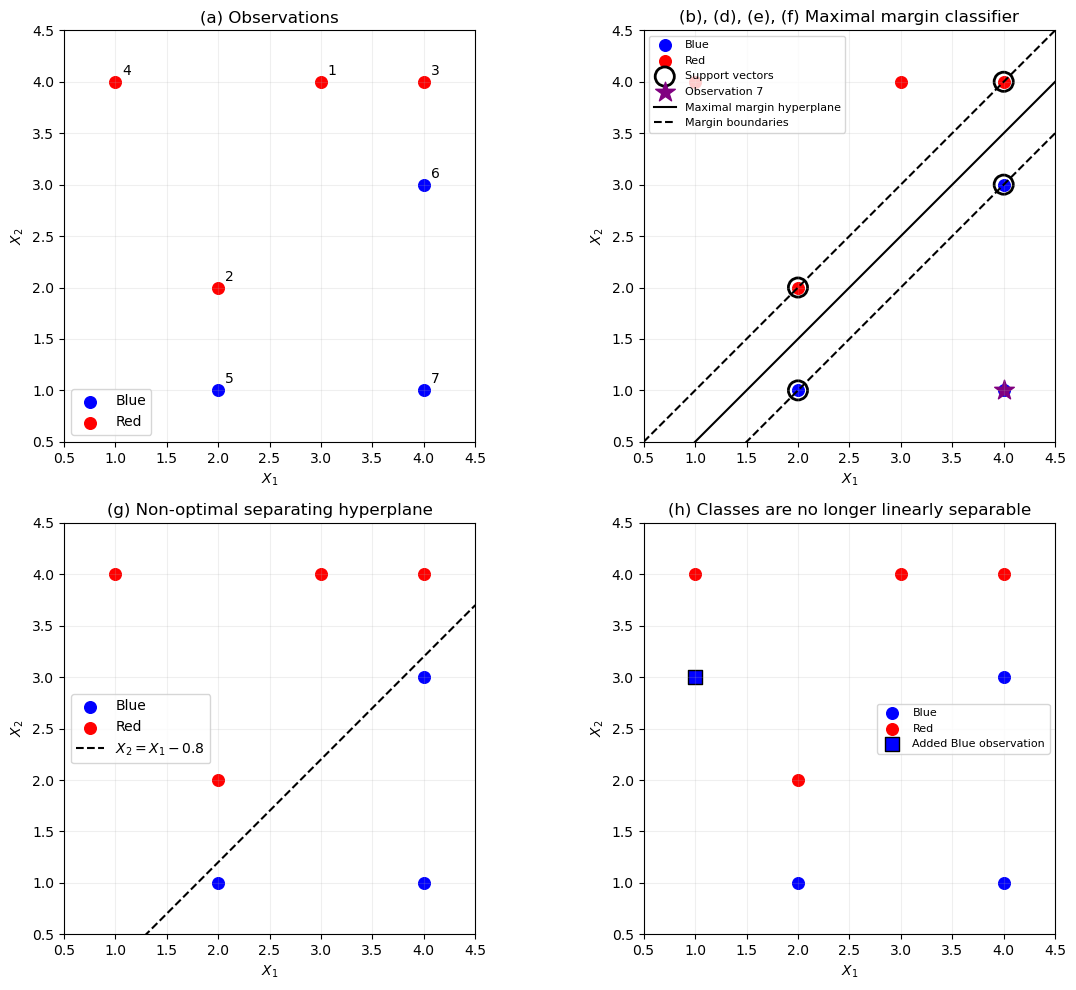

In [3]:
toy_data = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "Class": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"],
})

class_colors = {"Red": "red", "Blue": "blue"}
support_vector_indices = [1, 2, 4, 5]  # Zero-based indices: observations 2, 3, 5, 6
x_line = np.linspace(0.5, 4.5, 200)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# (a) Plot the observations
for class_name, group in toy_data.groupby("Class"):
    axes[0, 0].scatter(
        group["X1"],
        group["X2"],
        color=class_colors[class_name],
        label=class_name,
        s=70,
    )

for obs_number, row in toy_data.iterrows():
    axes[0, 0].annotate(
        str(obs_number + 1),
        (row["X1"], row["X2"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

axes[0, 0].set_title("(a) Observations")
axes[0, 0].legend()

# (b), (d), (e), and (f): optimal hyperplane, margins, and support vectors
for class_name, group in toy_data.groupby("Class"):
    axes[0, 1].scatter(
        group["X1"],
        group["X2"],
        color=class_colors[class_name],
        label=class_name,
        s=70,
    )

support_vectors = toy_data.iloc[support_vector_indices]
axes[0, 1].scatter(
    support_vectors["X1"],
    support_vectors["X2"],
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    s=190,
    label="Support vectors",
)

axes[0, 1].scatter(
    toy_data.loc[6, "X1"],
    toy_data.loc[6, "X2"],
    color="purple",
    marker="*",
    s=220,
    label="Observation 7",
)

axes[0, 1].plot(x_line, x_line - 0.5, "k-", label="Maximal margin hyperplane")
axes[0, 1].plot(x_line, x_line, "k--", label="Margin boundaries")
axes[0, 1].plot(x_line, x_line - 1, "k--")

axes[0, 1].set_title("(b), (d), (e), (f) Maximal margin classifier")
axes[0, 1].legend(fontsize=8)

# (g) A non-optimal separating hyperplane
for class_name, group in toy_data.groupby("Class"):
    axes[1, 0].scatter(
        group["X1"],
        group["X2"],
        color=class_colors[class_name],
        label=class_name,
        s=70,
    )

axes[1, 0].plot(x_line, x_line - 0.8, "k--", label=r"$X_2=X_1-0.8$")
axes[1, 0].set_title("(g) Non-optimal separating hyperplane")
axes[1, 0].legend()

# (h) Add a Blue observation that makes the classes inseparable
for class_name, group in toy_data.groupby("Class"):
    axes[1, 1].scatter(
        group["X1"],
        group["X2"],
        color=class_colors[class_name],
        label=class_name,
        s=70,
    )

axes[1, 1].scatter(
    1,
    3,
    color="blue",
    marker="s",
    edgecolors="black",
    s=110,
    label="Added Blue observation",
)

axes[1, 1].set_title("(h) Classes are no longer linearly separable")
axes[1, 1].legend(fontsize=8)

for ax in axes.flat:
    ax.set_xlim(0.5, 4.5)
    ax.set_ylim(0.5, 4.5)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()